In [1]:
#Importações
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Config. visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10,4)

#Leitura e visualização prévia
df = pd.read_csv('../data/raw/raw_csv_itbi.csv', sep=';', encoding='latin1', on_bad_lines='skip')
df.head()

,logradouro,numero,complemento,valor_avaliacao,bairro,cidade,uf,ano_construcao,area_terreno,area_construida,...,tipo_construcao,tipo_ocupacao,data_transacao,estado_conservacao,tipo_imovel,sfh,cod_logradouro,latitude,longitude,ano
0,av norte miguel arraes de alencar,3071,NaN,"1068562,63",Encruzilhada,Recife,PE,1997,438,511,...,GalpÃ£o,COMERCIAL SEM LIXO ORGANICO,2025-11-30,Regular,GalpÃ£o,"0,00",46540,-8.034273,-34.896337,2025
1,av norte miguel arraes de alencar,3071,NaN,"1068562,63",Encruzilhada,Recife,PE,1997,438,511,...,GalpÃ£o,COMERCIAL SEM LIXO ORGANICO,2025-11-30,Regular,GalpÃ£o,"0,00",46540,-8.034273,-34.896337,2025
2,av norte miguel arraes de alencar,3029,NaN,"1951000,00",Encruzilhada,Recife,PE,1957,"779,33","582,44",...,Casa,COMERCIAL SEM LIXO ORGANICO,2025-11-30,Regular,Casa,"0,00",46540,-8.034435,-34.896335,2025
3,rua caio pereira,375,apto 101 edf luar do rosarinho,"393452,82",Encruzilhada,Recife,PE,2007,"798,91","118,64",...,Apartamento > 4 Pavimentos,RESIDENCIAL,2025-11-28,Bom,Apartamento,"263000,00",13269,-8.034996,-34.896187,2025
4,rua caio pereira,375,apto 501 edf luar do rosarinho,"402821,74",Encruzilhada,Recife,PE,2007,"798,91","118,64",...,Apartamento > 4 Pavimentos,RESIDENCIAL,2025-10-02,Bom,Apartamento,"200000,00",13269,-8.034996,-34.896187,2025


In [3]:
#Conversão de tipo (usando referências brasileiras)
coluna_alvo = 'valor_avaliacao'
df['valor_avaliacao_raw'] = df[coluna_alvo] #Guardando coluna crua
tipo_original = df[coluna_alvo].dtype
print(f"Tipo original da coluna alvo: {tipo_original}")

df[coluna_alvo] = (
    df[coluna_alvo]
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
)
df[coluna_alvo] = pd.to_numeric(df[coluna_alvo], errors='coerce')
tipo_atual = df[coluna_alvo].dtype
print(f"Tipo atual da coluna alvo: {tipo_atual}")


Tipo original da coluna alvo: str
Tipo atual da coluna alvo: float64


In [4]:
#Descrição da coluna_alvo
estatisticas = df[coluna_alvo].describe()

#Contagens de qualidade e anomalias
total_instancias = len(df)
qtd_nulos = df[coluna_alvo].isnull().sum()
qtd_zeros = (df[coluna_alvo] == 0).sum()
qtd_negativos = (df[coluna_alvo] < 0).sum()

print (f"Número de instâncias: {total_instancias}\nqtd_nulos: {qtd_nulos}\nqtd_zeros: {qtd_zeros}\nqtd_negativos: {qtd_negativos}")

#IQR para indentificar outliers
q1 = df[coluna_alvo].quantile(0.25)
q3 = df[coluna_alvo].quantile(0.75)
iqr = q3-q1

limite_superior = q3 + 1.5*iqr
qtd_outliers = (df[coluna_alvo] > limite_superior).sum()
assimetria = df[coluna_alvo].skew()

print("\n=== ESTATÍSTICAS DESCRITIVAS ===")
print(estatisticas.map(lambda x: f"R$ {x:,.2f}"))

print("\n=== DETEÇÃO DE VALORES ABSURDOS (OUTLIERS) ===")
print(f"Q1 (25%): R$ {q1:,.2f}")
print(f"Q3 (75%): R$ {q3:,.2f}")
print(f"IQR: R$ {iqr:,.2f}")
print(f"Limite Superior (IQR): R$ {limite_superior:,.2f}")
print(f"Quantidade de Outliers acima do Limite Superior: {qtd_outliers} ({qtd_outliers/total_instancias:.2%})")
print(f"Assimetria (Skewness): {assimetria:.2f}")


Número de instâncias: 16318
qtd_nulos: 0
qtd_zeros: 0
qtd_negativos: 0

=== ESTATÍSTICAS DESCRITIVAS ===
count         R$ 16,318.00
mean         R$ 659,151.45
std        R$ 2,649,334.65
min               R$ 19.52
25%          R$ 241,976.38
50%          R$ 350,000.00
75%          R$ 570,000.00
max      R$ 135,926,576.00
Name: valor_avaliacao, dtype: str

=== DETEÇÃO DE VALORES ABSURDOS (OUTLIERS) ===
Q1 (25%): R$ 241,976.38
Q3 (75%): R$ 570,000.00
IQR: R$ 328,023.62
Limite Superior (IQR): R$ 1,062,035.43
Quantidade de Outliers acima do Limite Superior: 1658 (10.16%)
Assimetria (Skewness): 32.83


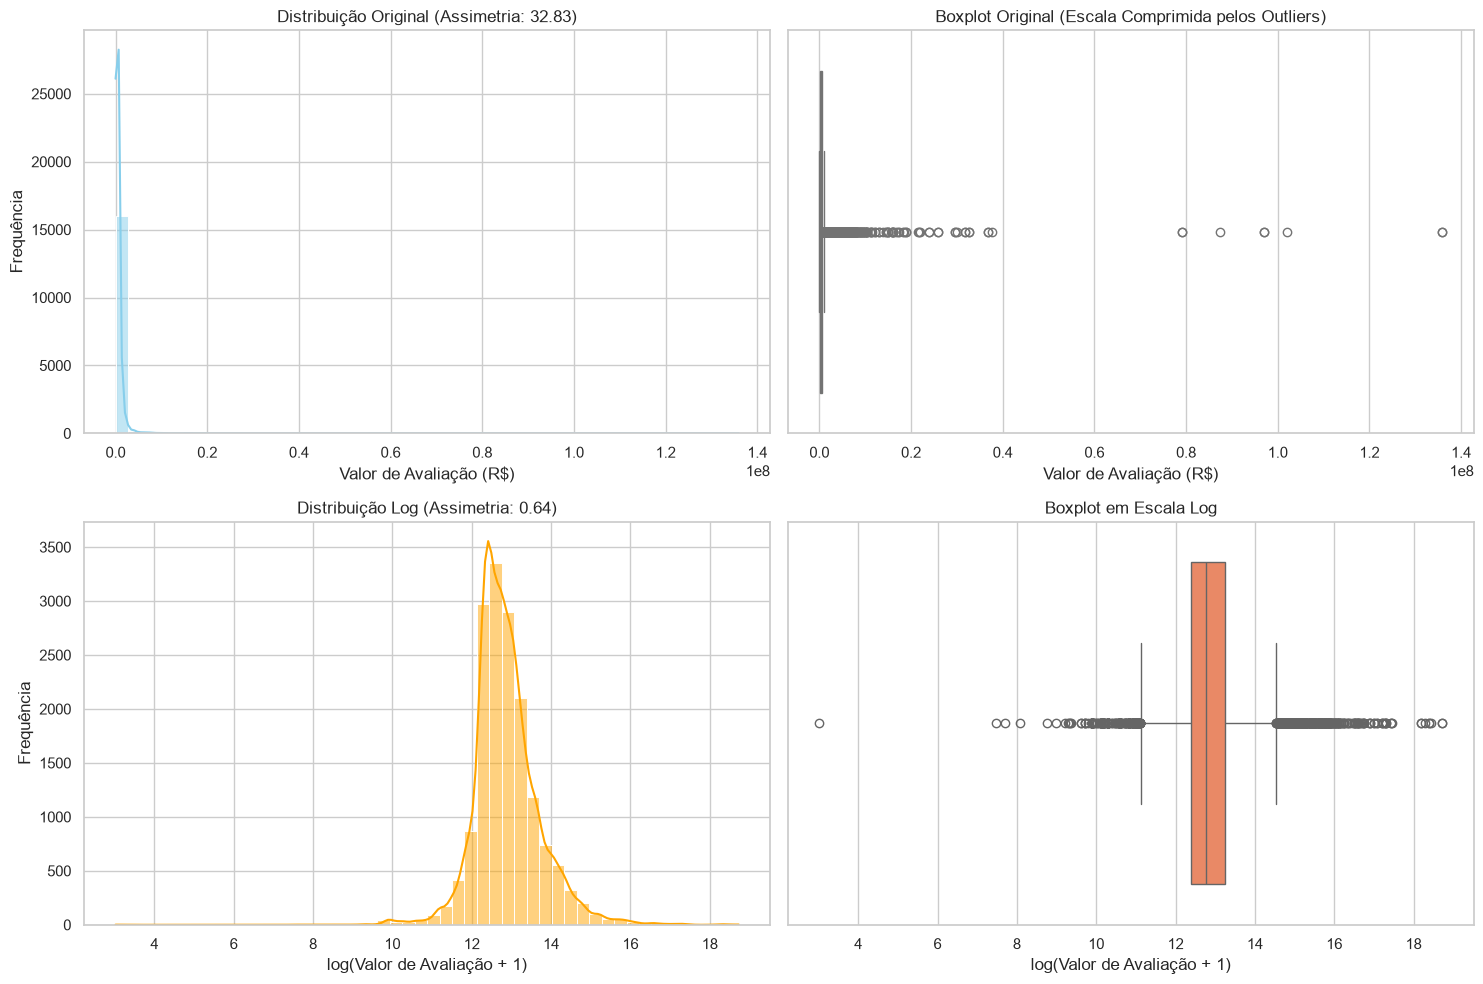

Nova Assimetria em Log: 0.64


In [5]:
#Aplicação de transformação logarítmica
df['valor_avaliacao_log'] = np.log1p(df[coluna_alvo])

#Configuração da figura com os 4 gráficos (2x2)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

#Graficos Originais
sns.histplot(df[coluna_alvo], kde=True, ax=axes[0, 0], color='skyblue', bins=50)
axes[0, 0].set_title(f'Distribuição Original (Assimetria: {df[coluna_alvo].skew():.2f})')
axes[0, 0].set_xlabel('Valor de Avaliação (R$)')
axes[0, 0].set_ylabel('Frequência')

sns.boxplot(x=df[coluna_alvo], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Boxplot Original (Escala Comprimida pelos Outliers)')
axes[0, 1].set_xlabel('Valor de Avaliação (R$)')

#Gráficos em escala log
sns.histplot(df['valor_avaliacao_log'], kde=True, ax=axes[1, 0], color='orange', bins=50)
axes[1, 0].set_title(f'Distribuição Log (Assimetria: {df["valor_avaliacao_log"].skew():.2f})')
axes[1, 0].set_xlabel('log(Valor de Avaliação + 1)')
axes[1, 0].set_ylabel('Frequência')

sns.boxplot(x=df['valor_avaliacao_log'], ax=axes[1, 1], color='coral')
axes[1, 1].set_title('Boxplot em Escala Log')
axes[1, 1].set_xlabel('log(Valor de Avaliação + 1)')

plt.tight_layout()
plt.show()

print(f"Nova Assimetria em Log: {df['valor_avaliacao_log'].skew():.2f}")

In [6]:
#Verificação do menor valor (R$ 19,52)
idx_min = df[coluna_alvo].idxmin()
print(f"Bruto: '{df.loc[idx_min, 'valor_avaliacao_raw']}' -> convertido: {df.loc[idx_min, coluna_alvo]}")
df = df.drop(columns=['valor_avaliacao_raw'])

Bruto: '19,52' -> convertido: 19.52


In [7]:
#Verificar se houve remoção de linhas na leitura do CSV
linhas_csv_original = sum(1 for _ in open('../data/raw/raw_csv_itbi.csv', encoding='latin1')) - 1 #desconsidera cabeçalho
print(f"Linhas no CSV original: {linhas_csv_original}")
print(f"Linhas no DataFrame carregado: {len(df)}")
print(f"Linhas descartadas: {linhas_csv_original - len(df)}")

Linhas no CSV original: 16318
Linhas no DataFrame carregado: 16318
Linhas descartadas: 0


In [8]:
#Contagem e percentuais de valores baixos
for limite in [1000, 10000, 50000]:
    qtd = (df[coluna_alvo] < limite).sum()
    pct = (qtd / len(df)) * 100
    print(f"Abaixo de R$ {limite:,.2f}: {qtd} imóveis ({pct:.3f}%)")

#Inspecionar as primeiras linhas dos valores mais baixos
df[df[coluna_alvo] < 1000].sort_values(by=coluna_alvo).head(10)

Abaixo de R$ 1,000.00: 1 imóveis (0.006%)
Abaixo de R$ 10,000.00: 7 imóveis (0.043%)
Abaixo de R$ 50,000.00: 133 imóveis (0.815%)


,logradouro,numero,complemento,valor_avaliacao,bairro,cidade,uf,ano_construcao,area_terreno,area_construida,...,tipo_ocupacao,data_transacao,estado_conservacao,tipo_imovel,sfh,cod_logradouro,latitude,longitude,ano,valor_avaliacao_log
14000,rua faustino porto,322,apto 401 golden city home service,19.52,Boa Viagem,Recife,PE,2013,1400,"62,67",...,RESIDENCIAL,2025-03-31,Bom,Apartamento,"0,00",23655,-8.117157,-34.898621,2025,3.0214


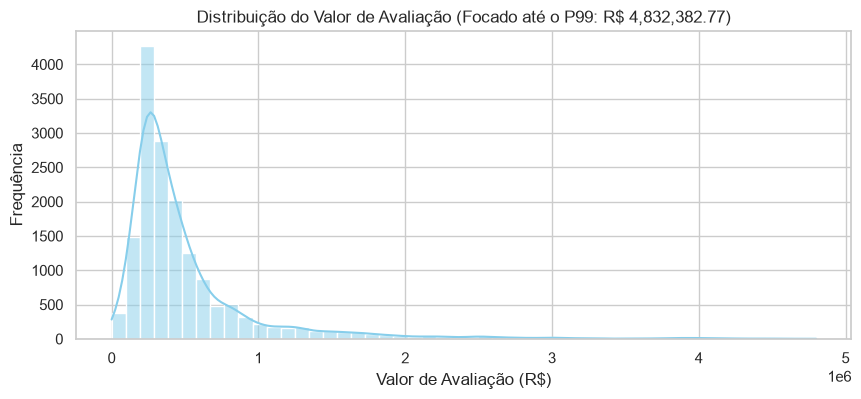

Valor do P99: R$ 4,832,382.77
Imóveis representados no gráfico (≤ P99): 16154 (99.0%)
Imóveis omitidos para fins de visualização (> P99): 164 (1.0%)


In [9]:
#Histograma da distribuição original cortado no Percentil 99 (P99)
p99 = df[coluna_alvo].quantile(0.99)

plt.figure(figsize=(10, 4))
sns.histplot(df[df[coluna_alvo] <= p99][coluna_alvo], kde=True, bins=50, color='skyblue')
plt.title(f'Distribuição do Valor de Avaliação (Focado até o P99: R$ {p99:,.2f})')
plt.xlabel('Valor de Avaliação (R$)')
plt.ylabel('Frequência')
plt.show()

print(f"Valor do P99: R$ {p99:,.2f}")
print(f"Imóveis representados no gráfico (≤ P99): {(df[coluna_alvo] <= p99).sum()} ({(df[coluna_alvo] <= p99).mean()*100:.1f}%)")
print(f"Imóveis omitidos para fins de visualização (> P99): {(df[coluna_alvo] > p99).sum()} ({(df[coluna_alvo] > p99).mean()*100:.1f}%)")

In [10]:
#Cálculo de Assimetria e Curtose (Original vs. Log)
skew_orig = df[coluna_alvo].skew()
skew_log = df['valor_avaliacao_log'].skew()

kurt_orig = df[coluna_alvo].kurt()
kurt_log = df['valor_avaliacao_log'].kurt()

print("=== COMPARAÇÃO DE FORMA DA DISTRIBUIÇÃO ===")
print(f"Original -> Assimetria: {skew_orig:.2f} | Curtose: {kurt_orig:.2f}")
print(f"Log      -> Assimetria: {skew_log:.2f} | Curtose: {kurt_log:.2f}")

=== COMPARAÇÃO DE FORMA DA DISTRIBUIÇÃO ===
Original -> Assimetria: 32.83 | Curtose: 1360.50
Log      -> Assimetria: 0.64 | Curtose: 5.16


In [11]:
q1_log = df['valor_avaliacao_log'].quantile(0.25)
q3_log = df['valor_avaliacao_log'].quantile(0.75)
iqr_log = q3_log - q1_log

lim_inf_log = q1_log - 1.5 * iqr_log
lim_sup_log = q3_log + 1.5 * iqr_log

#Converter os limites de volta para Reais com expm1
lim_inf_rs = np.expm1(lim_inf_log)
lim_sup_rs = np.expm1(lim_sup_log)

outliers_log = df[(df['valor_avaliacao_log'] < lim_inf_log) | (df['valor_avaliacao_log'] > lim_sup_log)]
pct_outliers_log = (len(outliers_log) / len(df)) * 100

abaixo = (df['valor_avaliacao_log'] < lim_inf_log).sum()
acima = (df['valor_avaliacao_log'] > lim_sup_log).sum()

print(f"Limite Inferior em Log convertido para R$: R$ {lim_inf_rs:,.2f}")
print(f"Limite Superior em Log convertido para R$: R$ {lim_sup_rs:,.2f}")
print(f"Outliers detectados na escala Log: {len(outliers_log)} ({pct_outliers_log:.2f}%)")
print(f"Abaixo do limite inferior: {abaixo} | Acima do limite superior: {acima}")

Limite Inferior em Log convertido para R$: R$ 66,929.41
Limite Superior em Log convertido para R$: R$ 2,060,756.47
Outliers detectados na escala Log: 750 (4.60%)
Abaixo do limite inferior: 191 | Acima do limite superior: 559


# Relatório de síntese: EDA da variável alvo (valor_avaliacao)

## 1. Qualidade dos dados
- 16.318 registros, sem nulos, zeros ou negativos, e nenhuma linha descartada na leitura do CSV.
- Menor valor: R$ 19,52 (1 registro), um apartamento de 62,67 m² em Boa Viagem. O CSV traz exatamente `19,52`, então não é artefato da conversão: trata-se de ruído/erro de registro, incompatível com o mercado.
- Apenas 7 imóveis (0,043%) ficam abaixo de R$ 10 mil e 133 (0,815%) abaixo de R$ 50 mil.

## 2. Distribuição
- Média de R$ 659.151 contra mediana de R$ 350.000 (1,9x), desvio-padrão de R$ 2,65 milhões e máximo de R$ 135,9 milhões.
- 1% dos imóveis (164) está acima de R$ 4,83 milhões (P99).
- Assimetria de 32,83 e curtose (excesso) de 1.360,5: cauda longa à direita, com poucos exemplos de alto valor. É o perfil de uma regressão com alvo desbalanceado.

## 3. Outliers
- IQR na escala original: limite superior de R$ 1.062.035 e 1.658 imóveis (10,16%). O valor é inflado pela própria assimetria.
- IQR na escala log: limites de R$ 66.929 e R$ 2.060.756, com 750 imóveis (4,60%): 191 (1,17%) abaixo do limite inferior e 559 (3,43%) acima do superior.
- **Decisão:** manter os valores altos. São imóveis de alto padrão legítimos, e removê-los descartaria justamente a região mais rara do alvo.
- **Proposta (a confirmar com o grupo):** remover o registro de R$ 19,52 e inspecionar os 7 abaixo de R$ 10 mil (área e tipo) antes de decidir sobre eles. Os demais imóveis da cauda inferior ficam, pois não há evidência de erro.

## 4. Transformação logarítmica (`np.log1p`)
- A assimetria cai de 32,83 para 0,64 e a curtose de 1.360,5 para 5,16. A distribuição fica aproximadamente em sino, mas ainda com caudas pesadas.
- No kNN, as distâncias são calculadas nas features, não no alvo. O log reduz a influência de valores extremos na média dos vizinhos e no erro, e passa a medir diferenças proporcionais. A média em log equivale a uma média geométrica dos vizinhos.
- O log muda a escala, não a quantidade de exemplos raros. Ele não substitui a reamostragem.

## 5. Encaminhamentos
- Testar nos experimentos: baseline sem tratamento, log, reamostragem para regressão (SMOTER/SMOGN) e a combinação. A reamostragem vale só no treino, dentro de cada fold.
- Reportar métricas em R$ (via `np.expm1`) e em log, e avaliar o erro por faixa de valor, não só MAE/RMSE globais.